# Laboratory 2

## 1.4

### 1. (1D) Minimize $f(x)=x^4-4x^2+x$

Derivatives:

$$f'(x)=4x^3-8x+1,\qquad f''(x)=12x^2-8.$$

The critical points are the roots of $4x^3-8x+1=0$ (the polynomial has no rational roots, so they are computed numerically). The second-derivative test classifies each one: $f''>0$ local minimum, $f''<0$ local maximum.

The global minimum is the lowest of the local minima.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

f   = lambda x: x**4 - 4*x**2 + x
fp  = lambda x: 4*x**3 - 8*x + 1
fpp = lambda x: 12*x**2 - 8

roots = np.sort(np.roots([4, 0, -8, 1]).real)

print(f"{'x*':>12} {'f(x*)':>12} {'f\'\'(x*)':>12}   classification")
for r in roots:
    kind = "local minimum" if fpp(r) > 0 else "local maximum"
    print(f"{r:12.6f} {f(r):12.6f} {fpp(r):12.6f}   {kind}")

x_global = roots[np.argmin(f(roots))]
print(f"\nGlobal minimum: x* = {x_global:.6f}, f(x*) = {f(x_global):.6f}")

          x*        f(x*)      f''(x*)   classification
   -1.472998    -5.444192    18.036663   local minimum
    0.126000     0.062748    -7.809487   local maximum
    1.346997    -2.618556    13.772824   local minimum

Global minimum: x* = -1.472998, f(x*) = -5.444192


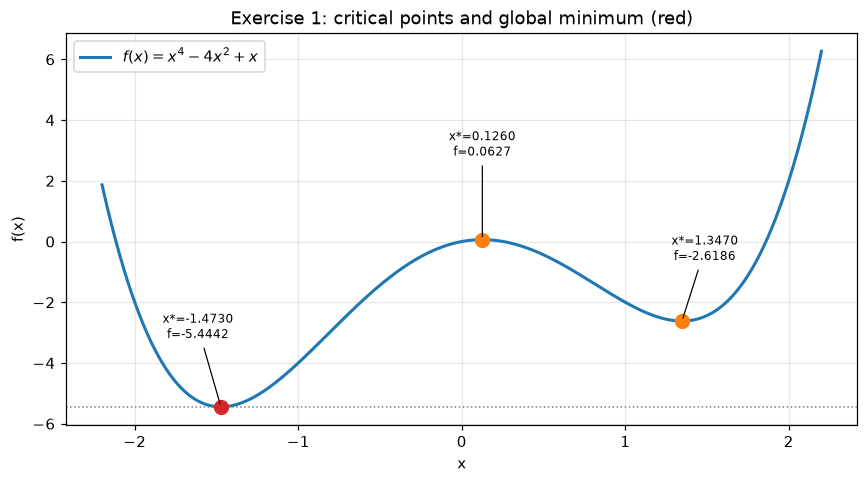

In [2]:
xs = np.linspace(-2.2, 2.2, 800)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(xs, f(xs), lw=2, label=r"$f(x)=x^4-4x^2+x$")

offsets = [(-15, 45), (0, 55), (15, 40)]
for r, off in zip(roots, offsets):
    ax.scatter(r, f(r), s=80, zorder=3,
               color="tab:red" if r == x_global else "tab:orange")
    ax.annotate(f"x*={r:.4f}\nf={f(r):.4f}", (r, f(r)),
                textcoords="offset points", xytext=off, ha="center",
                fontsize=8, arrowprops=dict(arrowstyle="-", lw=0.8))

ax.axhline(f(x_global), ls=":", color="gray", lw=1)
ax.set_xlabel("x"); ax.set_ylabel("f(x)")
ax.set_title("Exercise 1: critical points and global minimum (red)")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

### 2. (2D) Minimize $f(x,y)=x^2+xy+y^2-4x-6y$

Gradient:

$$\nabla f(x,y)=\begin{bmatrix}2x+y-4\\ x+2y-6\end{bmatrix}.$$

Solving $\nabla f=0$:

$$\begin{cases}2x+y=4\\ x+2y=6\end{cases}\;\Longrightarrow\;(x^*,y^*)=\left(\tfrac{2}{3},\tfrac{8}{3}\right).$$

Hessian (constant):

$$H=\begin{bmatrix}2&1\\1&2\end{bmatrix},\qquad \lambda_1=1,\ \lambda_2=3>0.$$

$H$ is positive definite on all of $\mathbb{R}^2$, so the critical point is a strict local minimum and, since $f$ is a convex quadratic, it is also the **global minimum**. Minimum value: $f(2/3,8/3)=-28/3\approx-9.3333$.

In [3]:
grad = lambda x, y: np.array([2*x + y - 4, x + 2*y - 6])
f2   = lambda x, y: x**2 + x*y + y**2 - 4*x - 6*y

H = np.array([[2.0, 1.0], [1.0, 2.0]])
p = np.linalg.solve(H, np.array([4.0, 6.0]))

print("Critical point (x*, y*) =", p)
print("∇f(x*, y*) =", grad(*p))
print("Hessian:\n", H)
print("Eigenvalues:", np.linalg.eigvalsh(H))
print("D = f_xx f_yy - f_xy² =", np.linalg.det(H))
print(f"f(x*, y*) = {f2(*p):.6f}")

Critical point (x*, y*) = [0.66666667 2.66666667]
∇f(x*, y*) = [0. 0.]
Hessian:
 [[2. 1.]
 [1. 2.]]
Eigenvalues: [1. 3.]
D = f_xx f_yy - f_xy² = 2.9999999999999996
f(x*, y*) = -9.333333


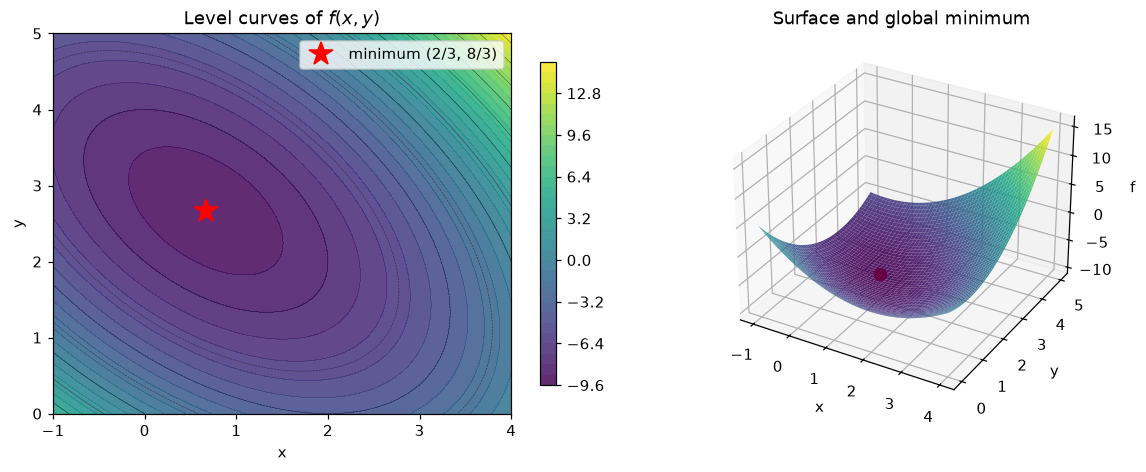

In [4]:
from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

gx, gy = np.meshgrid(np.linspace(-1, 4, 150), np.linspace(0, 5, 150))
gz = f2(gx, gy)

fig = plt.figure(figsize=(11, 4.4))

ax1 = fig.add_subplot(1, 2, 1)
cf = ax1.contourf(gx, gy, gz, levels=30, cmap="viridis", alpha=0.85)
ax1.contour(gx, gy, gz, levels=15, colors="k", linewidths=0.4, alpha=0.5)
ax1.plot(*p, "r*", ms=16, label=r"minimum $(2/3,\,8/3)$")
ax1.set_xlabel("x"); ax1.set_ylabel("y")
ax1.set_title("Level curves of $f(x,y)$")
ax1.legend(); fig.colorbar(cf, ax=ax1, shrink=0.85)

ax2 = fig.add_subplot(1, 2, 2, projection="3d")
ax2.plot_surface(gx, gy, gz, cmap="viridis", alpha=0.9, linewidth=0)
ax2.scatter(*p, f2(*p), color="red", s=60, zorder=5)
ax2.set_xlabel("x"); ax2.set_ylabel("y"); ax2.set_zlabel("f")
ax2.set_title("Surface and global minimum")

plt.tight_layout(); plt.show()

## Brief conclusions

- **1D:** there are three critical points: two local minima ($x\approx-1.4730$ and $x\approx1.3470$) and one local maximum ($x\approx0.1260$). The global minimum is $x^*\approx-1.4730$ with $f(x^*)\approx-5.4442$, since the function grows to $+\infty$ at both ends.
- **2D:** the only critical point is $(2/3,\,8/3)$; the constant positive-definite Hessian guarantees that it is the global minimum, with $f_{\min}=-28/3$.

---

## 2.2 Python exercise: pseudoinverse vs `lstsq`

The goal is to numerically solve

$$\min_x \|Ax-y\|_2^2$$

in two ways: with the pseudoinverse (`np.linalg.pinv(A) @ y`) and with `np.linalg.lstsq`. We also compare two regimes:

- **Overdetermined** ($m>n$): there are more measurements than unknowns; normally a unique least-squares solution exists.
- **Underdetermined** ($m<n$): there are fewer measurements than unknowns; there are infinitely many solutions that fit the data, and the pseudoinverse returns the one with **minimum norm**.

In [5]:
import numpy as np
import matplotlib.pyplot as plt

SIGMA = 0.05


def run_case(m, n, seed):
    # Generate y = A x_true + noise and solve with pinv and lstsq.
    rng = np.random.default_rng(seed)

    A = rng.standard_normal((m, n))
    x_true = rng.standard_normal(n)
    y = A @ x_true + SIGMA * rng.standard_normal(m)

    x_pinv = np.linalg.pinv(A) @ y
    x_lstsq = np.linalg.lstsq(A, y, rcond=None)[0]

    def relative_error(x):
        return np.linalg.norm(x - x_true) / np.linalg.norm(x_true)

    def residual(x):
        return np.linalg.norm(A @ x - y)

    return {
        "m": m, "n": n,
        "A": A, "x_true": x_true, "y": y,
        "x_pinv": x_pinv, "x_lstsq": x_lstsq,
        "rel_pinv": relative_error(x_pinv),
        "rel_lstsq": relative_error(x_lstsq),
        "res_pinv": residual(x_pinv),
        "res_lstsq": residual(x_lstsq),
    }


cases = {
    "m > n": run_case(80, 20, seed=1),
    "m < n": run_case(20, 80, seed=2),
}

print(f"{'case':<6} {'method':<8} {'rel. error':>12} {'residual':>12}")
print("-" * 42)
for name, r in cases.items():
    print(f"{name:<6} {'pinv':<8} {r['rel_pinv']:12.3e} {r['res_pinv']:12.3e}")
    print(f"{'':<6} {'lstsq':<8} {r['rel_lstsq']:12.3e} {r['res_lstsq']:12.3e}")

print("\nMaximum difference between pinv and lstsq:")
for name, r in cases.items():
    diff = np.linalg.norm(r["x_pinv"] - r["x_lstsq"])
    print(f"  {name}: {diff:.2e}")

case   method     rel. error     residual
------------------------------------------
m > n  pinv        4.471e-03    4.148e-01
       lstsq       4.471e-03    4.148e-01
m < n  pinv        8.928e-01    4.759e-14
       lstsq       8.928e-01    4.578e-14

Maximum difference between pinv and lstsq:
  m > n: 1.01e-14
  m < n: 5.46e-15


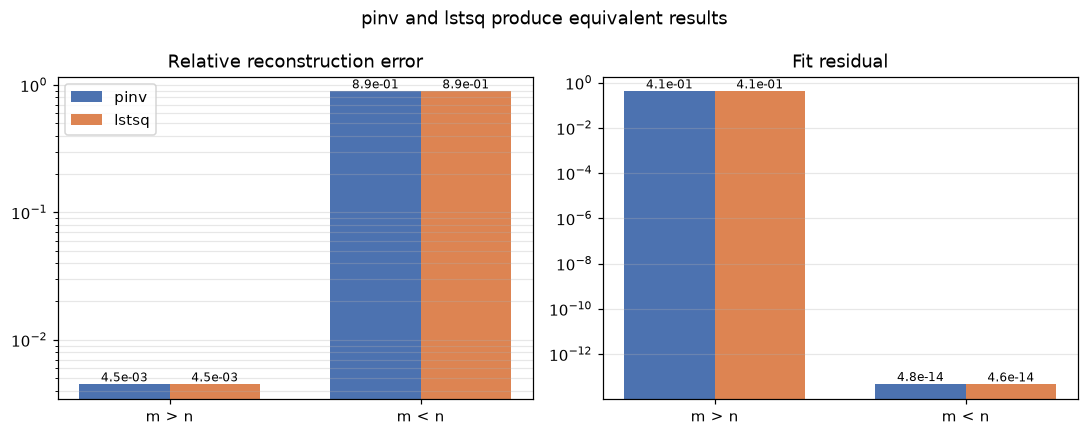

In [6]:
names = list(cases.keys())
pos = np.arange(len(names))
width = 0.36

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, key, title in zip(
    axes,
    ["rel", "res"],
    ["Relative reconstruction error", "Fit residual"],
):
    values_pinv = [cases[k][key + "_pinv"] for k in names]
    values_lstsq = [cases[k][key + "_lstsq"] for k in names]

    ax.bar(pos - width / 2, values_pinv, width,
           label="pinv", color="#4C72B0")
    ax.bar(pos + width / 2, values_lstsq, width,
           label="lstsq", color="#DD8452")

    ax.set_xticks(pos, ["m > n", "m < n"])
    ax.set_yscale("log")
    ax.set_title(title)
    ax.grid(axis="y", which="both", alpha=0.3)

    for x, v in zip(pos - width / 2, values_pinv):
        ax.text(x, v, f"{v:.1e}", ha="center", va="bottom", fontsize=8)
    for x, v in zip(pos + width / 2, values_lstsq):
        ax.text(x, v, f"{v:.1e}", ha="center", va="bottom", fontsize=8)

axes[0].legend()
fig.suptitle("pinv and lstsq produce equivalent results")
fig.tight_layout()
plt.show()

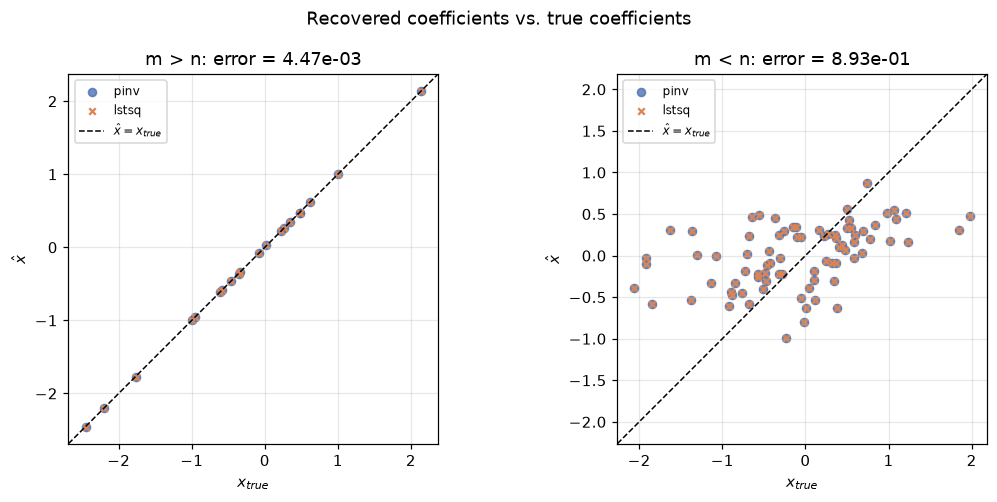

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.6))

for ax, (name, r) in zip(axes, cases.items()):
    ax.scatter(r["x_true"], r["x_pinv"], s=28, alpha=0.8,
               label="pinv", color="#4C72B0")
    ax.scatter(r["x_true"], r["x_lstsq"], s=18, marker="x",
               label="lstsq", color="#DD8452")

    minimum = min(r["x_true"].min(), r["x_pinv"].min(), r["x_lstsq"].min())
    maximum = max(r["x_true"].max(), r["x_pinv"].max(), r["x_lstsq"].max())
    margin = 0.05 * (maximum - minimum)

    ax.plot([minimum - margin, maximum + margin],
            [minimum - margin, maximum + margin],
            "k--", lw=1, label=r"$\hat{x}=x_{true}$")

    ax.set_xlim(minimum - margin, maximum + margin)
    ax.set_ylim(minimum - margin, maximum + margin)
    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel(r"$x_{true}$")
    ax.set_ylabel(r"$\hat{x}$")
    ax.set_title(f"{name}: error = {r['rel_pinv']:.2e}")
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc="upper left")

fig.suptitle("Recovered coefficients vs. true coefficients")
fig.tight_layout()
plt.show()

### Observations

- `pinv` and `lstsq` agree to machine precision in both cases.
- **Case $m>n$:** the system has a unique least-squares solution; the relative error is small ($\approx 4.5\times10^{-3}$) and the residual is on the order of the noise.
- **Case $m<n$:** the residual is essentially zero because the noise can always be fitted exactly, but the relative error is large ($\approx 0.89$). The pseudoinverse returns the **minimum-norm** solution, not the true one; recovering it would require additional information or regularization.
- For $m<n$, $\|x_{pinv}\|=3.35$ compared with $\|x_{true}\|=7.46$; another solution that also fits the data can have norm $15.30$ and residual $\sim10^{-14}$. This confirms that `pinv` chooses the minimum-norm solution.
- Both systems are well conditioned ($\text{cond}(A)\approx 3$): for $m<n$ the problem is not one of numerical ill-conditioning, but of **lack of information**.